# Task 2 · Overfitting
The Task 1 CNN against a larger CNN (1.5× wider convolutions, 2× wider FC layer, 2.9× the parameters) and the smaller
CNN of the search, all trained with the same 5 folds and schedule as in Task 1; then the large CNN with dropout or with
weight decay.

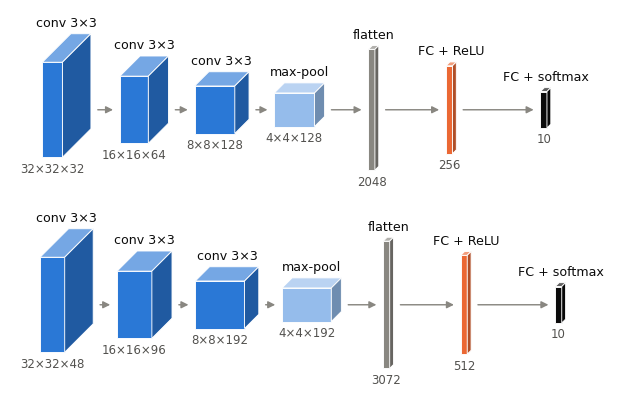

In [1]:
from hw3 import *

B = json.load(open(BEST))['cnn']
large = dict(model=partial(CNN, 48, 512), lr=B['lr'])
S = {'small': dict(model=partial(CNN, 16), lr=B['lr']), 'base': dict(model=partial(CNN, B['arch']), lr=B['lr']),
     'large': large, 'dropout': large | dict(model=partial(CNN, 48, 512, .5)), 'wd': large | dict(wd=.5)}
key = {'small': f"cnn_16-32-64_{B['lr']:g}", 'base': B['key'], 'large': 'large', 'dropout': 'large_dropout', 'wd': 'large_wd'}
R = cv({key[k]: S[k] for k in S})
R = {k: R[key[k]] for k in S}
diagram('arch_large', [cnn_layers(B['arch']), cnn_layers(48, 512)])

Generalization loss $GL(t) = 100\,(L_{val}(t) / \min_{s \le t} L_{val}(s) - 1)$: how far, in %, the validation loss is
above the best value seen so far. Overfitting starts at the first epoch from which $GL$ stays above 5% to the end.

In [2]:
ALPHA = 5
gl = lambda r: 100 * (np.asarray(r['val_loss']) / np.minimum.accumulate(np.asarray(r['val_loss'])) - 1)


def onset(r):
    above = gl(r) > ALPHA
    return len(above) - np.argmin(above[::-1]) + 1 if above[-1] else np.nan


ons = {k: np.array([onset(r) for r in R[k]], float) for k in R}
pd.DataFrame(ons, index=[f'fold {f + 1}' for f in range(FOLDS)])

,small,base,large,dropout,wd
fold 1,NaN,NaN,9.0,NaN,NaN
fold 2,NaN,NaN,NaN,NaN,NaN
fold 3,NaN,NaN,10.0,NaN,NaN
fold 4,NaN,NaN,9.0,NaN,NaN
fold 5,NaN,NaN,9.0,NaN,NaN


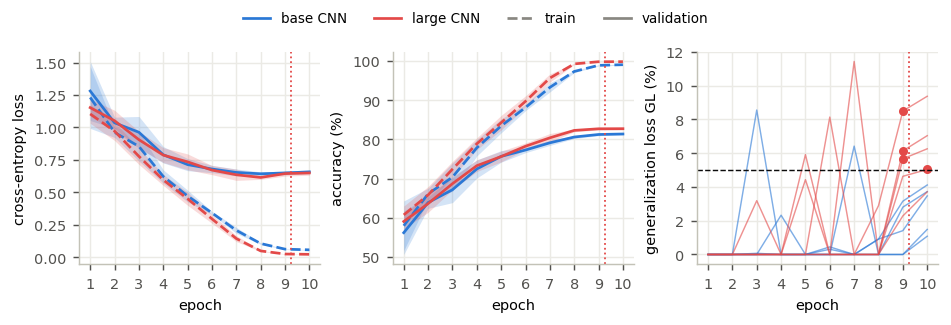

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), sharex=True)
G = {'base CNN': ('base', COL['cnn']), 'large CNN': ('large', COL['large'])}
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes[:2])
for n, c in G.values():
    g, o = np.stack([gl(r) for r in R[n]]), ons[n]
    axes[2].plot(range(1, g.shape[1] + 1), g.T, color=c, lw=.8, alpha=.6)
    axes[2].plot(o, [g[f, int(e) - 1] if e > 0 else np.nan for f, e in enumerate(o)], 'o', ms=4, color=c)
    if np.isfinite(o).any():
        for ax in axes:
            ax.axvline(np.nanmean(o), color=c, ls=':', lw=1)
axes[2].axhline(ALPHA, color=INK, ls='--', lw=.8)
axes[2].set(xlabel='epoch', ylabel='generalization loss GL (%)')
save(fig, 'overfit')

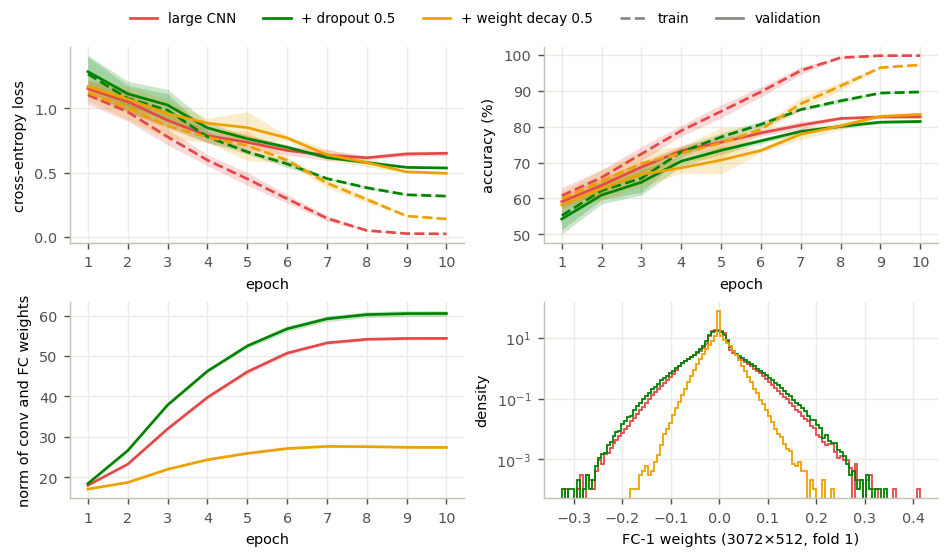

In [4]:
G = {'large CNN': ('large', COL['large']), '+ dropout 0.5': ('dropout', COL['dropout']),
     '+ weight decay 0.5': ('wd', COL['wd'])}
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.2))
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes[0])
W = {n: load(key[n], S[n]['model'])[5].weight.detach().flatten().numpy() for n, _ in G.values()}
bins = np.histogram_bin_edges(np.concatenate(list(W.values())), 120)
for n, c in G.values():
    band(axes[1, 0], R[n], 'wnorm', c)
    axes[1, 1].hist(W[n], bins, histtype='step', color=c, density=True)
axes[1, 0].set(xlabel='epoch', ylabel='norm of conv and FC weights')
axes[1, 1].set(xlabel='FC-1 weights (3072×512, fold 1)', ylabel='density', yscale='log')
save(fig, 'regularize')

In [5]:
on = lambda k: 'none' if np.isnan(ons[k]).all() else f'{ms(ons[k][np.isfinite(ons[k])], 1)} in {np.isfinite(ons[k]).sum()}/{FOLDS}'
T = pd.DataFrame({k: {'params (M)': f"{R[k][0]['params'] / 1e6:.2f}", 'train acc': ms(last(R[k], 'train_acc')),
                      'val acc': ms(last(R[k], 'val_acc')), 'test acc': ms(last(R[k], 'test_acc')),
                      'gap (pp)': ms(last(R[k], 'train_acc') - last(R[k], 'val_acc')),
                      'best val loss': ms([r['val_loss'].min().item() for r in R[k]], 1, 3),
                      'final val loss': ms(last(R[k], 'val_loss'), 1, 3), 'onset epoch': on(k)} for k in R}).T
rows('t2_table', T.set_axis(['Small CNN', 'Base CNN', 'Large CNN', '+ dropout', '+ weight decay']))
tex('t2', glAlpha=ALPHA, largeDiff=pdiff(R['large'], R['base']), dropoutDiff=pdiff(R['dropout'], R['large']),
    wdDiff=pdiff(R['wd'], R['large']), **{k + n: T[c][k] for k in R for n, c in (
        ('Onset', 'onset epoch'), ('Gap', 'gap (pp)'), ('Test', 'test acc'), ('Loss', 'final val loss'))})
T

,params (M),train acc,val acc,test acc,gap (pp),best val loss,final val loss,onset epoch
small,0.29,95.5 (0.3),78.3 (0.4),77.9 (0.4),17.3 (0.5),0.695 (0.011),0.702 (0.013),none
base,0.62,99.1 (0.1),81.4 (0.2),81.0 (0.3),17.7 (0.2),0.640 (0.013),0.658 (0.014),none
large,1.79,99.8 (0.1),82.7 (0.3),82.4 (0.2),17.1 (0.3),0.612 (0.021),0.650 (0.017),9.2 (0.5) in 4/5
dropout,1.79,89.7 (0.2),81.5 (0.5),81.1 (0.3),8.2 (0.4),0.535 (0.006),0.535 (0.006),none
wd,1.79,97.2 (0.2),83.4 (0.3),83.0 (0.2),13.8 (0.3),0.494 (0.008),0.494 (0.008),none
